# Crop Prediction using Machine Learning 

**Dataset:** Soil & climate features mapped to 22 African crop types  
**Goal:** Train and compare three ML classifiers, select the best, and deploy with Streamlit  
**Columns:** `N`, `P`, `K` (soil nutrients), `temperature`, `ph`, `rainfall` -> `crop` (target)


In [1]:
# Import necessary libraries for data manipulation, visualization, and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings, os, joblib

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (10, 5)})


## 1. Data Loading & Inspection

In [2]:
# Load dataset
df = pd.read_excel("../NEW DATASET.xlsx") 
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()


Shape: 3,056 rows × 8 columns


,N,P,K,temperature,humidity,ph,rainfall,crop
0,21,30.41,14,21.33,162.04,5.92,85.24,Tomato
1,24,33.67,13,20.20,210.18,5.73,84.02,Tomato
2,12,29.30,13,20.26,168.29,5.97,87.31,Tomato
3,20,31.04,14,21.46,142.52,5.91,86.84,Tomato
4,25,28.25,13,20.62,171.71,5.72,87.78,Tomato


In [3]:
# Basic info on the dataset
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3056 entries, 0 to 3055
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            3056 non-null   int64  
 1   P            3056 non-null   float64
 2   K            3056 non-null   int64  
 3   temperature  3056 non-null   float64
 4   humidity     3056 non-null   float64
 5   ph           3056 non-null   float64
 6   rainfall     3056 non-null   float64
 7   crop         3056 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 191.1+ KB


In [4]:
# Statistical summary on the dataset
df.describe().round(3)


,N,P,K,temperature,humidity,ph,rainfall
count,3056.000,3056.000,3056.000,3056.000,3056.000,3056.000,3056.000
mean,52.008,49.276,46.895,24.764,97.626,6.375,97.088
std,37.001,29.206,49.526,4.649,61.992,1.606,48.088
min,0.000,5.000,5.000,8.826,14.258,3.505,20.211
25%,21.000,29.015,19.000,21.670,63.186,5.895,68.706
50%,39.000,44.000,30.000,24.413,84.171,6.270,85.280
75%,84.000,61.000,50.000,27.521,98.092,6.726,109.820
max,179.000,145.000,250.000,43.675,299.130,86.000,298.560


### Macronutrients (N: Nitrogen, P: Phosphorus, K: Potassium):

**N (Nitrogen):** Mean 52.0, ranges 0–179. Wide spread (std 37.0) indicates diverse soil conditions

**P (Phosphorus):** Mean 59.3, ranges 5–145. More concentrated than N (std 29.2)

**K (Potassium):** Mean 46.9, ranges 5–250. Highest variability (std 49.5), with extreme values suggesting diverse crops/regions

<br/>

### Environmental Factors:

**Temperature:** Mean 25.9°C, ranges 8.8–43.7°C. Low std (4.9) = consistent climate zone. 50% of data falls between 23–28.6°C

**Humidity:** Mean 97.5%, ranges 14–299.1%. Std of 62.0% suggests high variability, likely due to seasonal or regional differences

**pH:** Mean 6.4 (slightly acidic). Concerning: range includes 3.5–86, with max value (86) being an outlier, normal soil pH is 3–9

**Rainfall:** Mean 103.5mm, ranges 20–298.6mm. Std of 55mm shows moderate variation in precipitation patterns

<br/>

### Data Characteristics

**Right-skewed distributions:** Most variables show mean > median (50%), indicating longer upper tails (outliers on high end)

**Outliers present:** pH max of 86 is unrealistic and should be investigated

**Good diversity:** Wide ranges suggest the dataset covers multiple crops, seasons, and geographic regions

In [5]:
# Missing values
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print(f"\nTotal missing: {missing.sum()}")


Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
crop           0
dtype: int64

Total missing: 0


There are no missing values in the dataset, and it contains 2200 rows and 7 columns. The target variable `crop` has 22 unique classes, with a fairly balanced distribution across them. The features include soil nutrients (N, P, K), temperature, pH, and rainfall, which are all relevant for predicting crop types.

In [6]:
# Class distribution
print(f"Unique crops : {df['crop'].nunique()}")
print("\nCrop value counts:")
print(df['crop'].value_counts())


Unique crops : 27

Crop value counts:
crop
Tomato              250
Groundnut           250
Cocoa               249
rice                100
watermelon          100
potato              100
coffee              100
jute/ewedu          100
cotton              100
coconut             100
papaya              100
orange              100
palm tree           100
muskmelon           100
grapes              100
maize               100
banana              100
cashew              100
beni/sesame seed    100
black beans         100
mungbean            100
mothbeans           100
pigeonpeas          100
kidneybeans         100
chickpea            100
mango               100
cassava/yam           7
Name: count, dtype: int64


## 2. Exploratory Data Analysis (EDA)

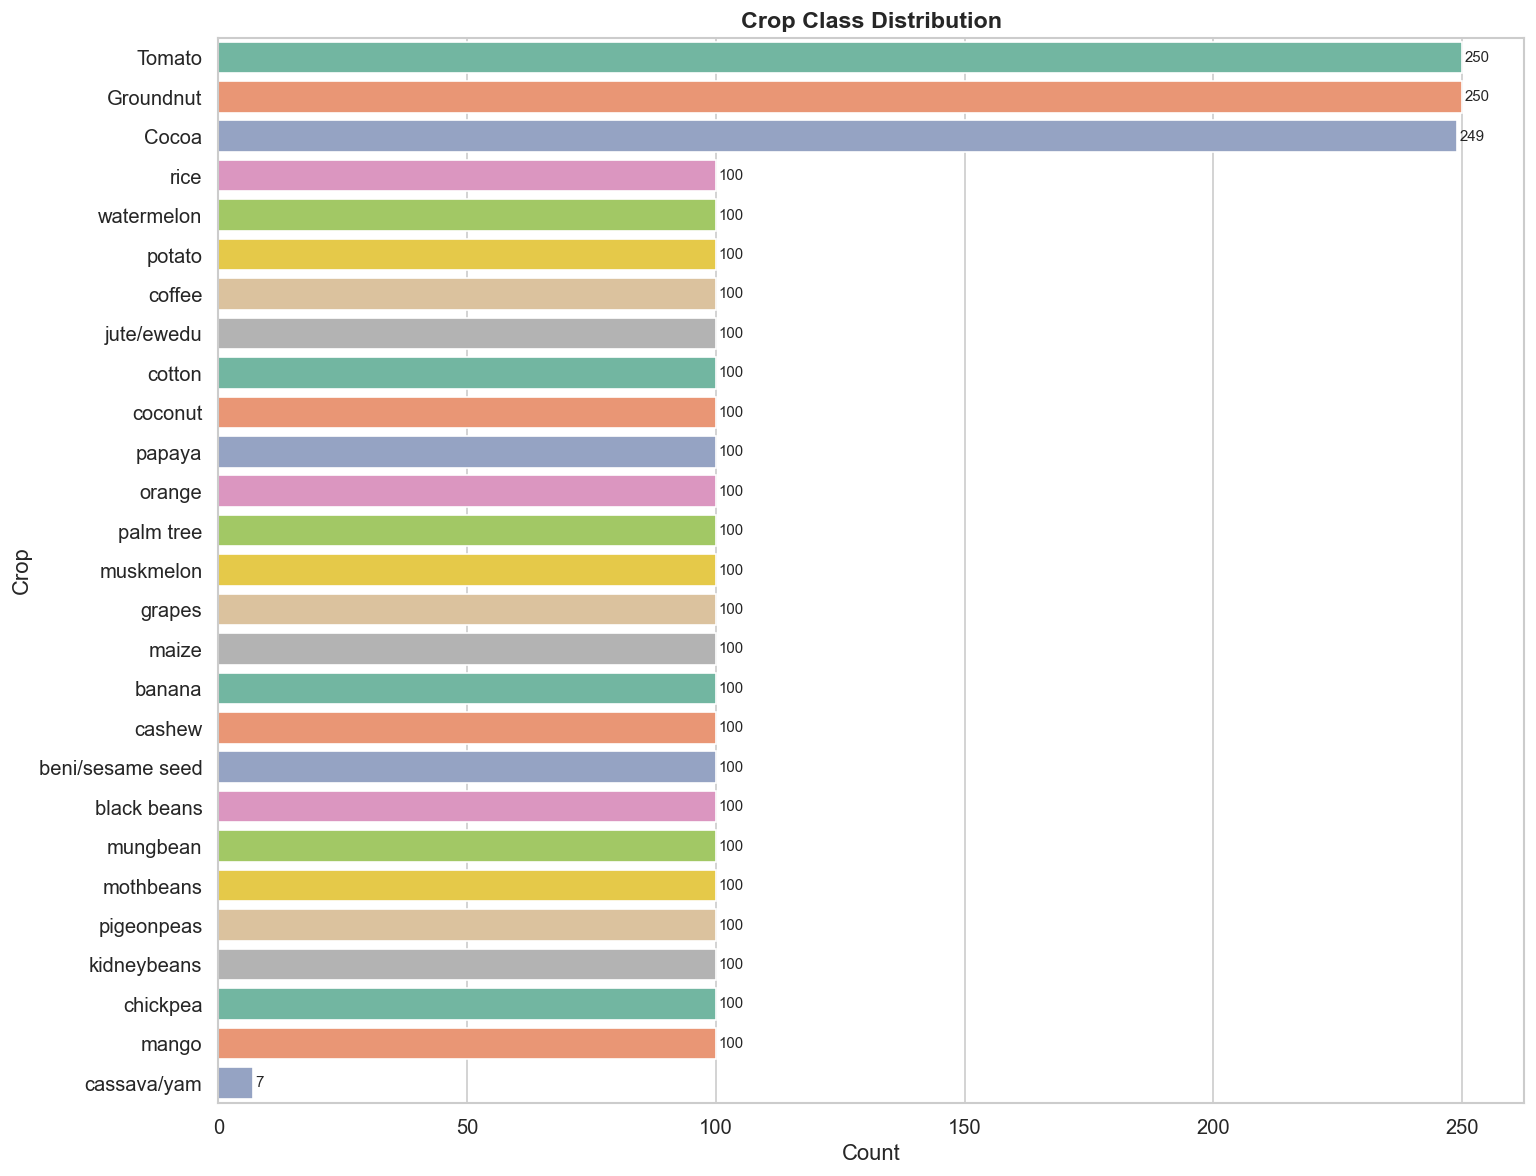

In [7]:
# Crop class distribution bar chart
fig, ax = plt.subplots(figsize=(13, 10))
order = df['crop'].value_counts().index
sns.countplot(data=df, y='crop', order=order, palette='Set2', ax=ax)
ax.set_title("Crop Class Distribution", fontsize=14, fontweight='bold')
ax.set_xlabel("Count")
ax.set_ylabel("Crop")
for bar in ax.patches:
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{int(bar.get_width())}', va='center', fontsize=9)
plt.tight_layout()
plt.show()


As shown in the class distribution plot, cassava/yam is significantly underrepresented with only 7 samples, while other crops have 100 or more samples. We see some crops have over 100 sample, we will need to carry out some data undersampling as well. This imbalance may affect model performance, so we will consider strategies to address it during model training.

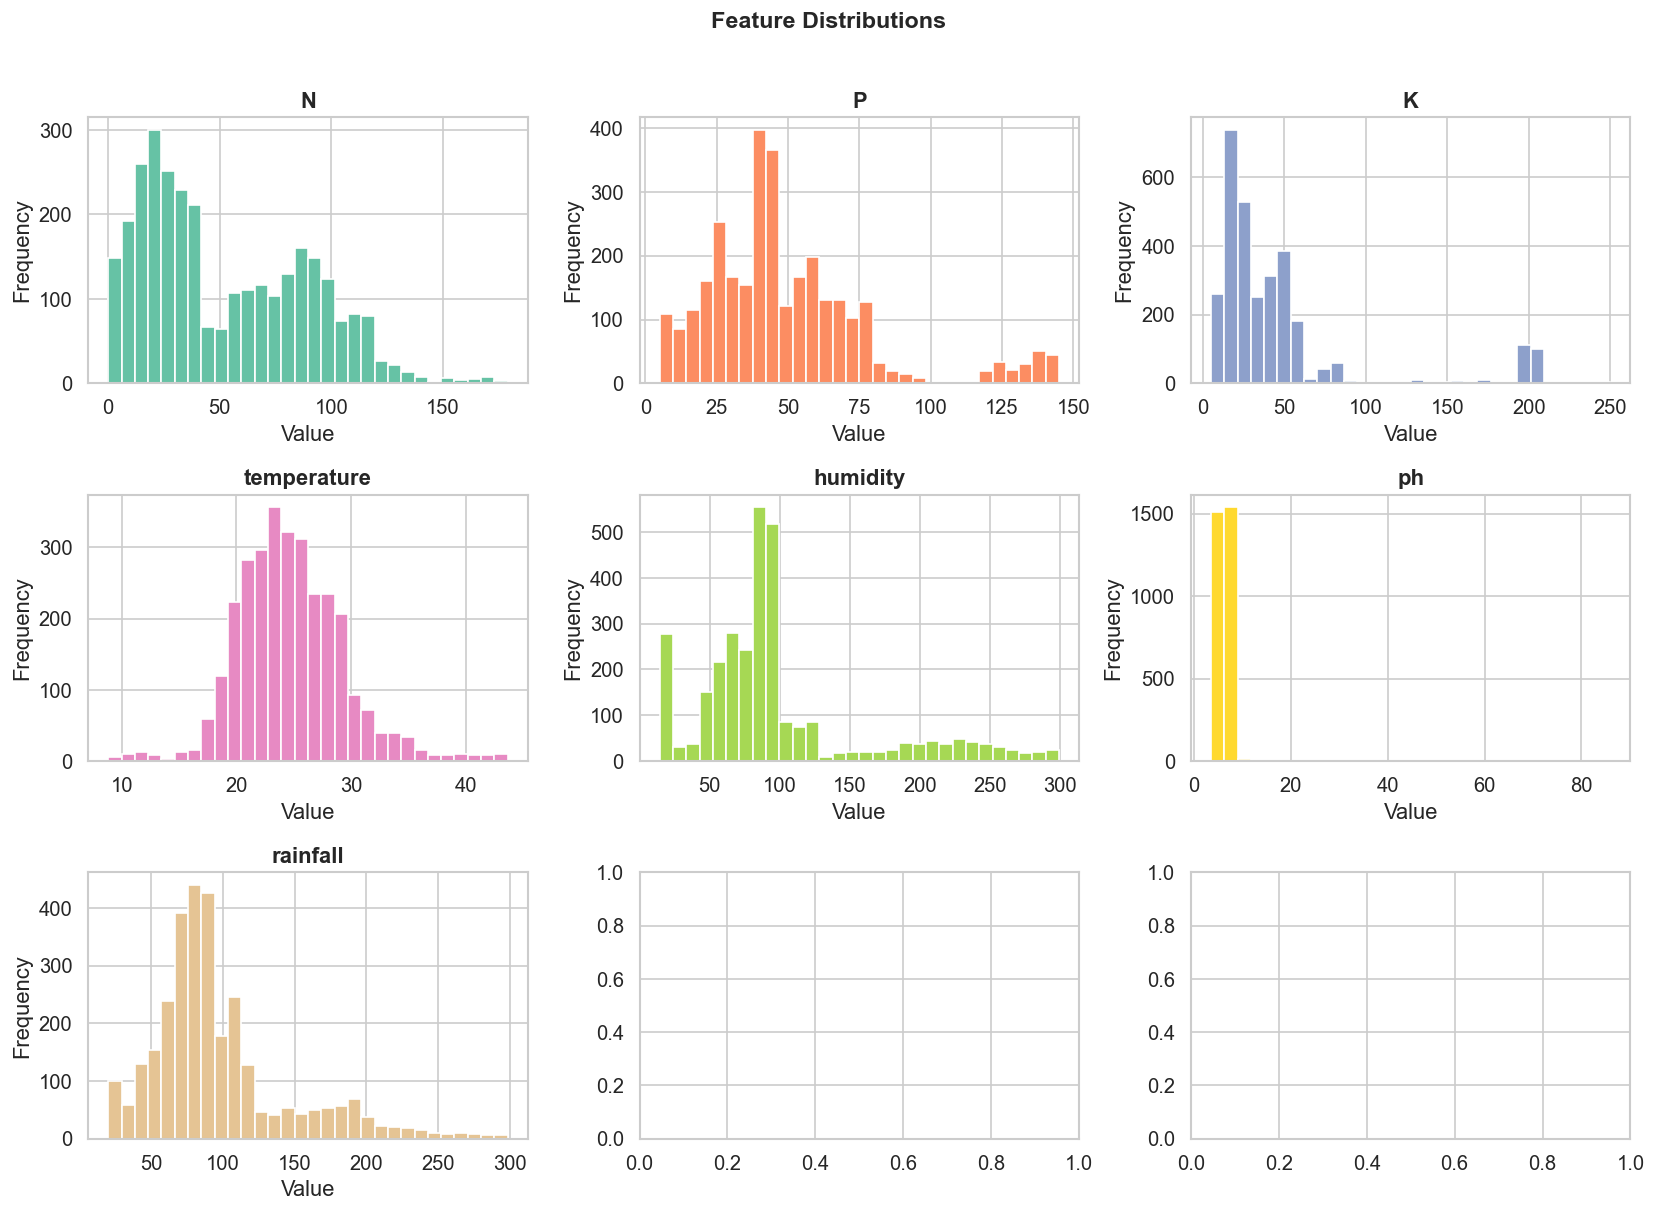

In [8]:
# Feature distributions (histograms)
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    axes[i].hist(df[col], bins=30, color=sns.color_palette("Set2")[i], edgecolor='white')
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
plt.suptitle("Feature Distributions", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**N (Nitrogen):** it is right-skewed with most crops needing low-to-moderate nitrogen (0–50 range). A secondary cluster around 80–130 represents high-nitrogen-demanding crops like banana, coffee, and potato. The bimodal shape is a strong signal that N is a highly discriminative feature.

**P (Phosphorus):** Roughly bell-shaped but with a suspicious gap between ~100–125, then a second cluster at 125–145. That high-P cluster is almost certainly grapes and muskmelon (confirmed by P Levels per Crop). P has good class-separating power.

**K (Potassium):** Highly right-skewed — the vast majority of crops sit in 5–60, with a very sparse but significant tail at 200+. Those extreme K values belong to grapes and muskmelon. K is one of the most discriminative features in the dataset precisely because of this.

**Temperature:** Near-normal distribution centred around 25°C, ranging 8–44°C. The reasonably Gaussian shape means most crops share similar temperature ranges, making it a weaker standalone feature, but it still contributes in combination (e.g. pawpaw uniquely extends to 40°C+).

**Humidity:** Shows two major groups, approximately 50–100% and 150–250%. This suggests different environmental or measurement conditions, but unusually high values above 100% need validation.

**pH:** This is the most important observation, the chart is dominated by two towering bars near 0–10, with the x-axis stretching all the way to 80+. This is the visual proof of the outlier (pH = 86) that needs to be cleaned. After cleaning, pH is actually a tight, fairly normal distribution around 6.0–7.5, which is typical agronomic range.

**Rainfall:** Bimodal distribution with peaks around 60–70mm and 95–105mm, then a smaller cluster near 200–210mm. Rice (very high rainfall ~200–300mm) and muskmelon (very low rainfall ~30–40mm) sit at the extremes, making rainfall one of the most class-separating features.

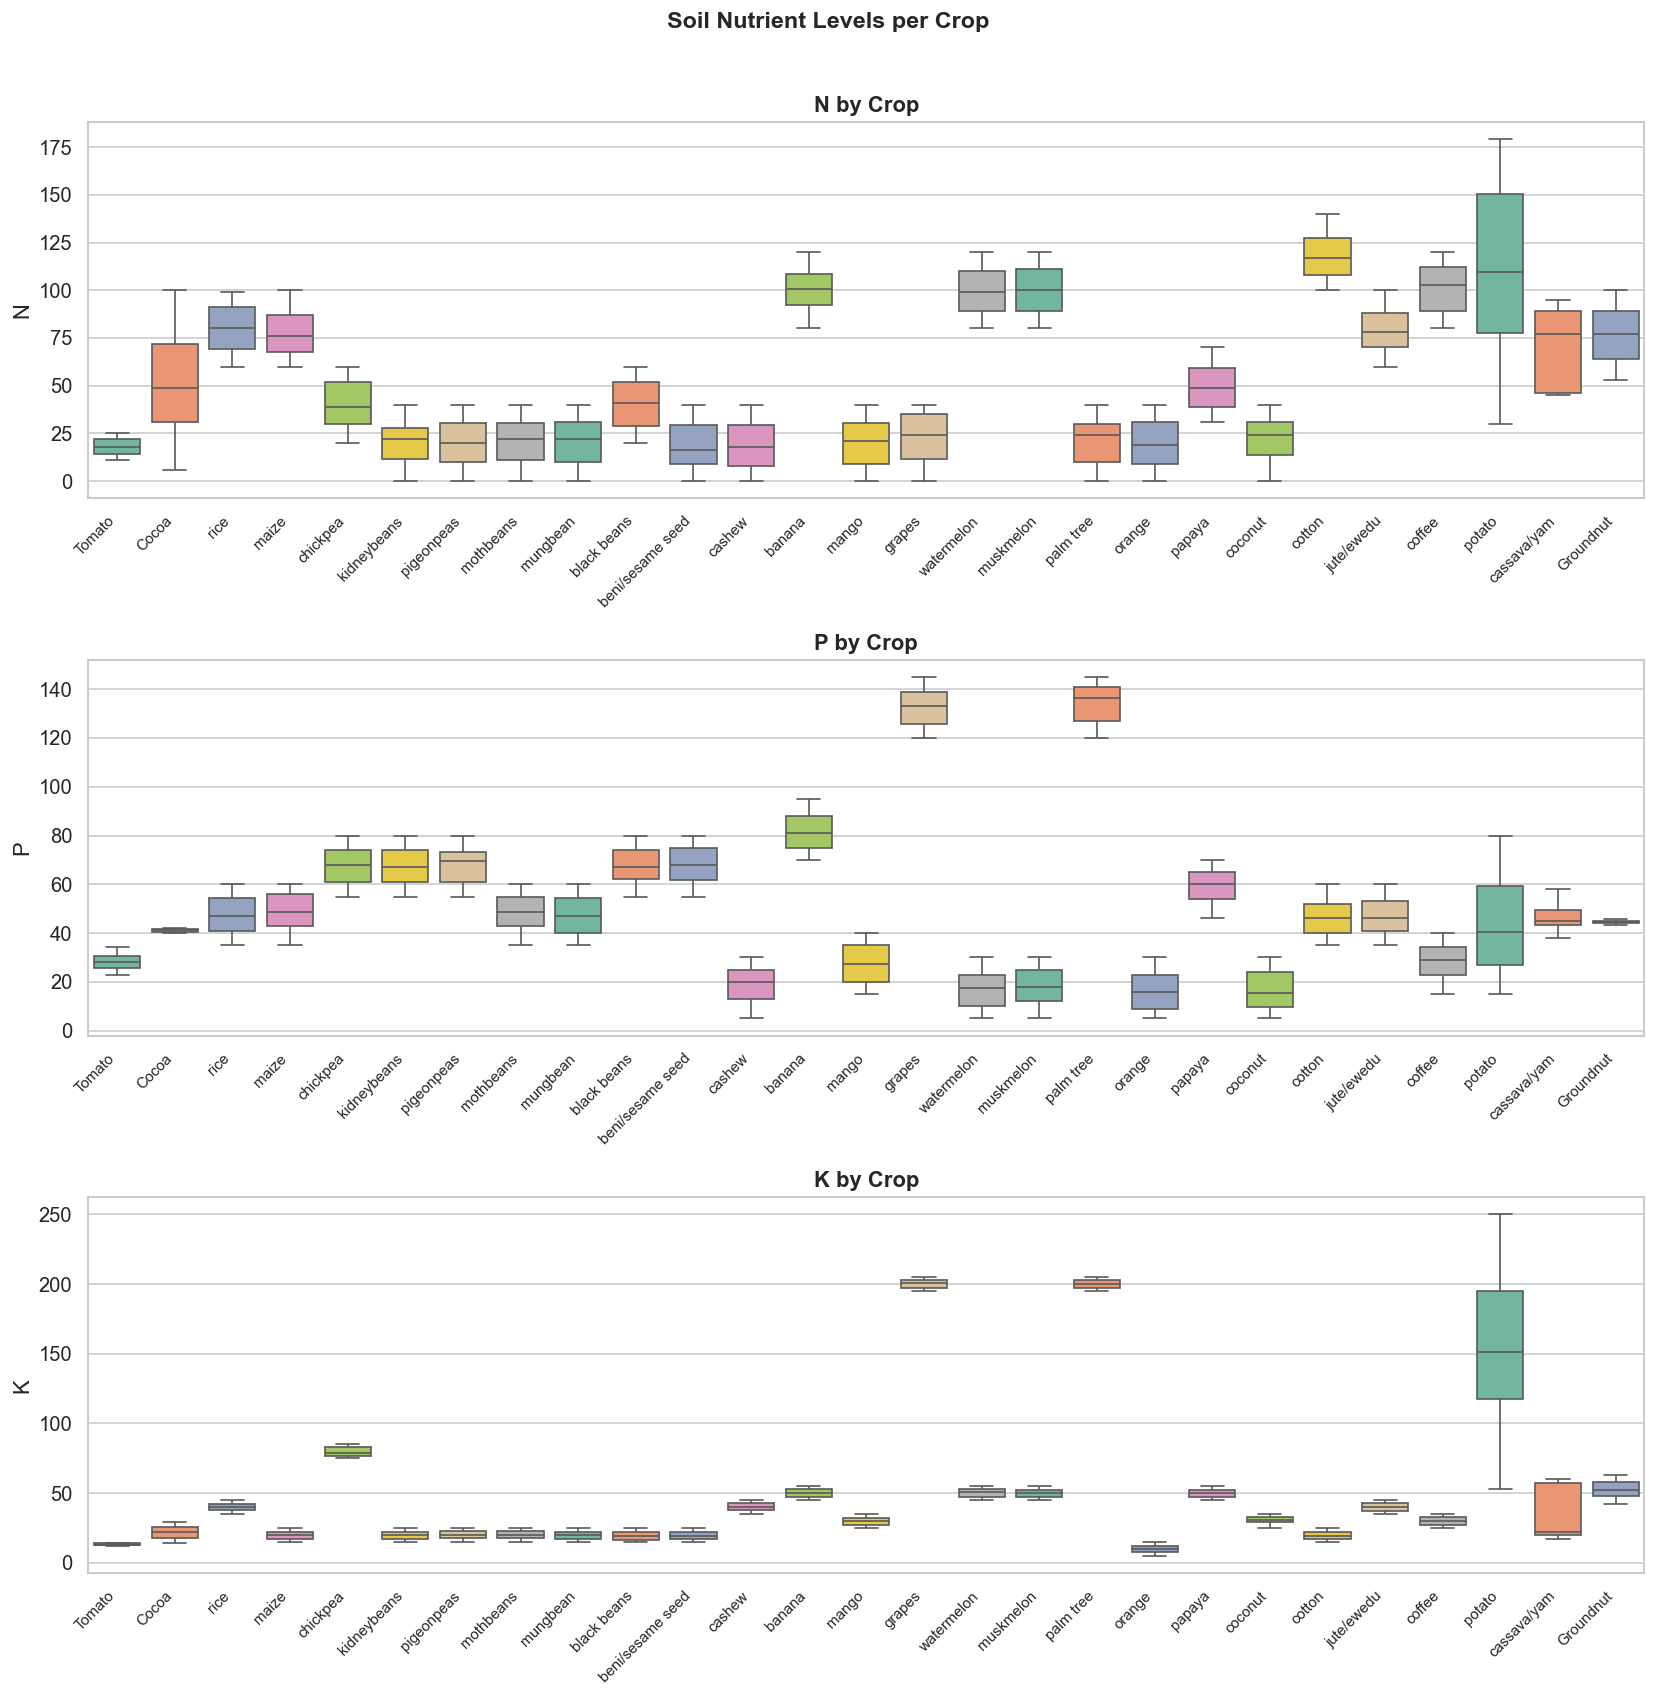

In [9]:
# Boxplots by crop (N, P, K)
fig, axes = plt.subplots(3, 1, figsize=(14, 14))
for ax, col in zip(axes, ['N', 'P', 'K']):
    sns.boxplot(data=df, x='crop', y=col, palette='Set2', ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax.set_title(f'{col} by Crop', fontweight='bold')
    ax.set_xlabel("")
plt.suptitle("Soil Nutrient Levels per Crop", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**N by Crop:** Muskmelon and watermelon generally require lower nitrogen, while grapes, rice, and potato have high and more variable requirements.
Banana and cotton also show relatively high nitrogen levels. Crops with short boxes have more consistent nitrogen needs; taller boxes indicate greater variation.

**P by Crop:** Grapes and palm tree stand out with clearly the highest phosphorus requirements. Muskmelon, papaya, and several beans also have moderate-to-high phosphorus levels. Most crops cluster between roughly 20 and 80, so P is useful for separating the very high-P crops.

**K by Crop:** Grapes and palm tree have exceptionally high potassium levels, making them easy to distinguish from most crops. Potato also has a wide K range and can require anywhere from moderate to very high potassium. Most other crops have consistently low potassium requirements between approximately 5 and 60.

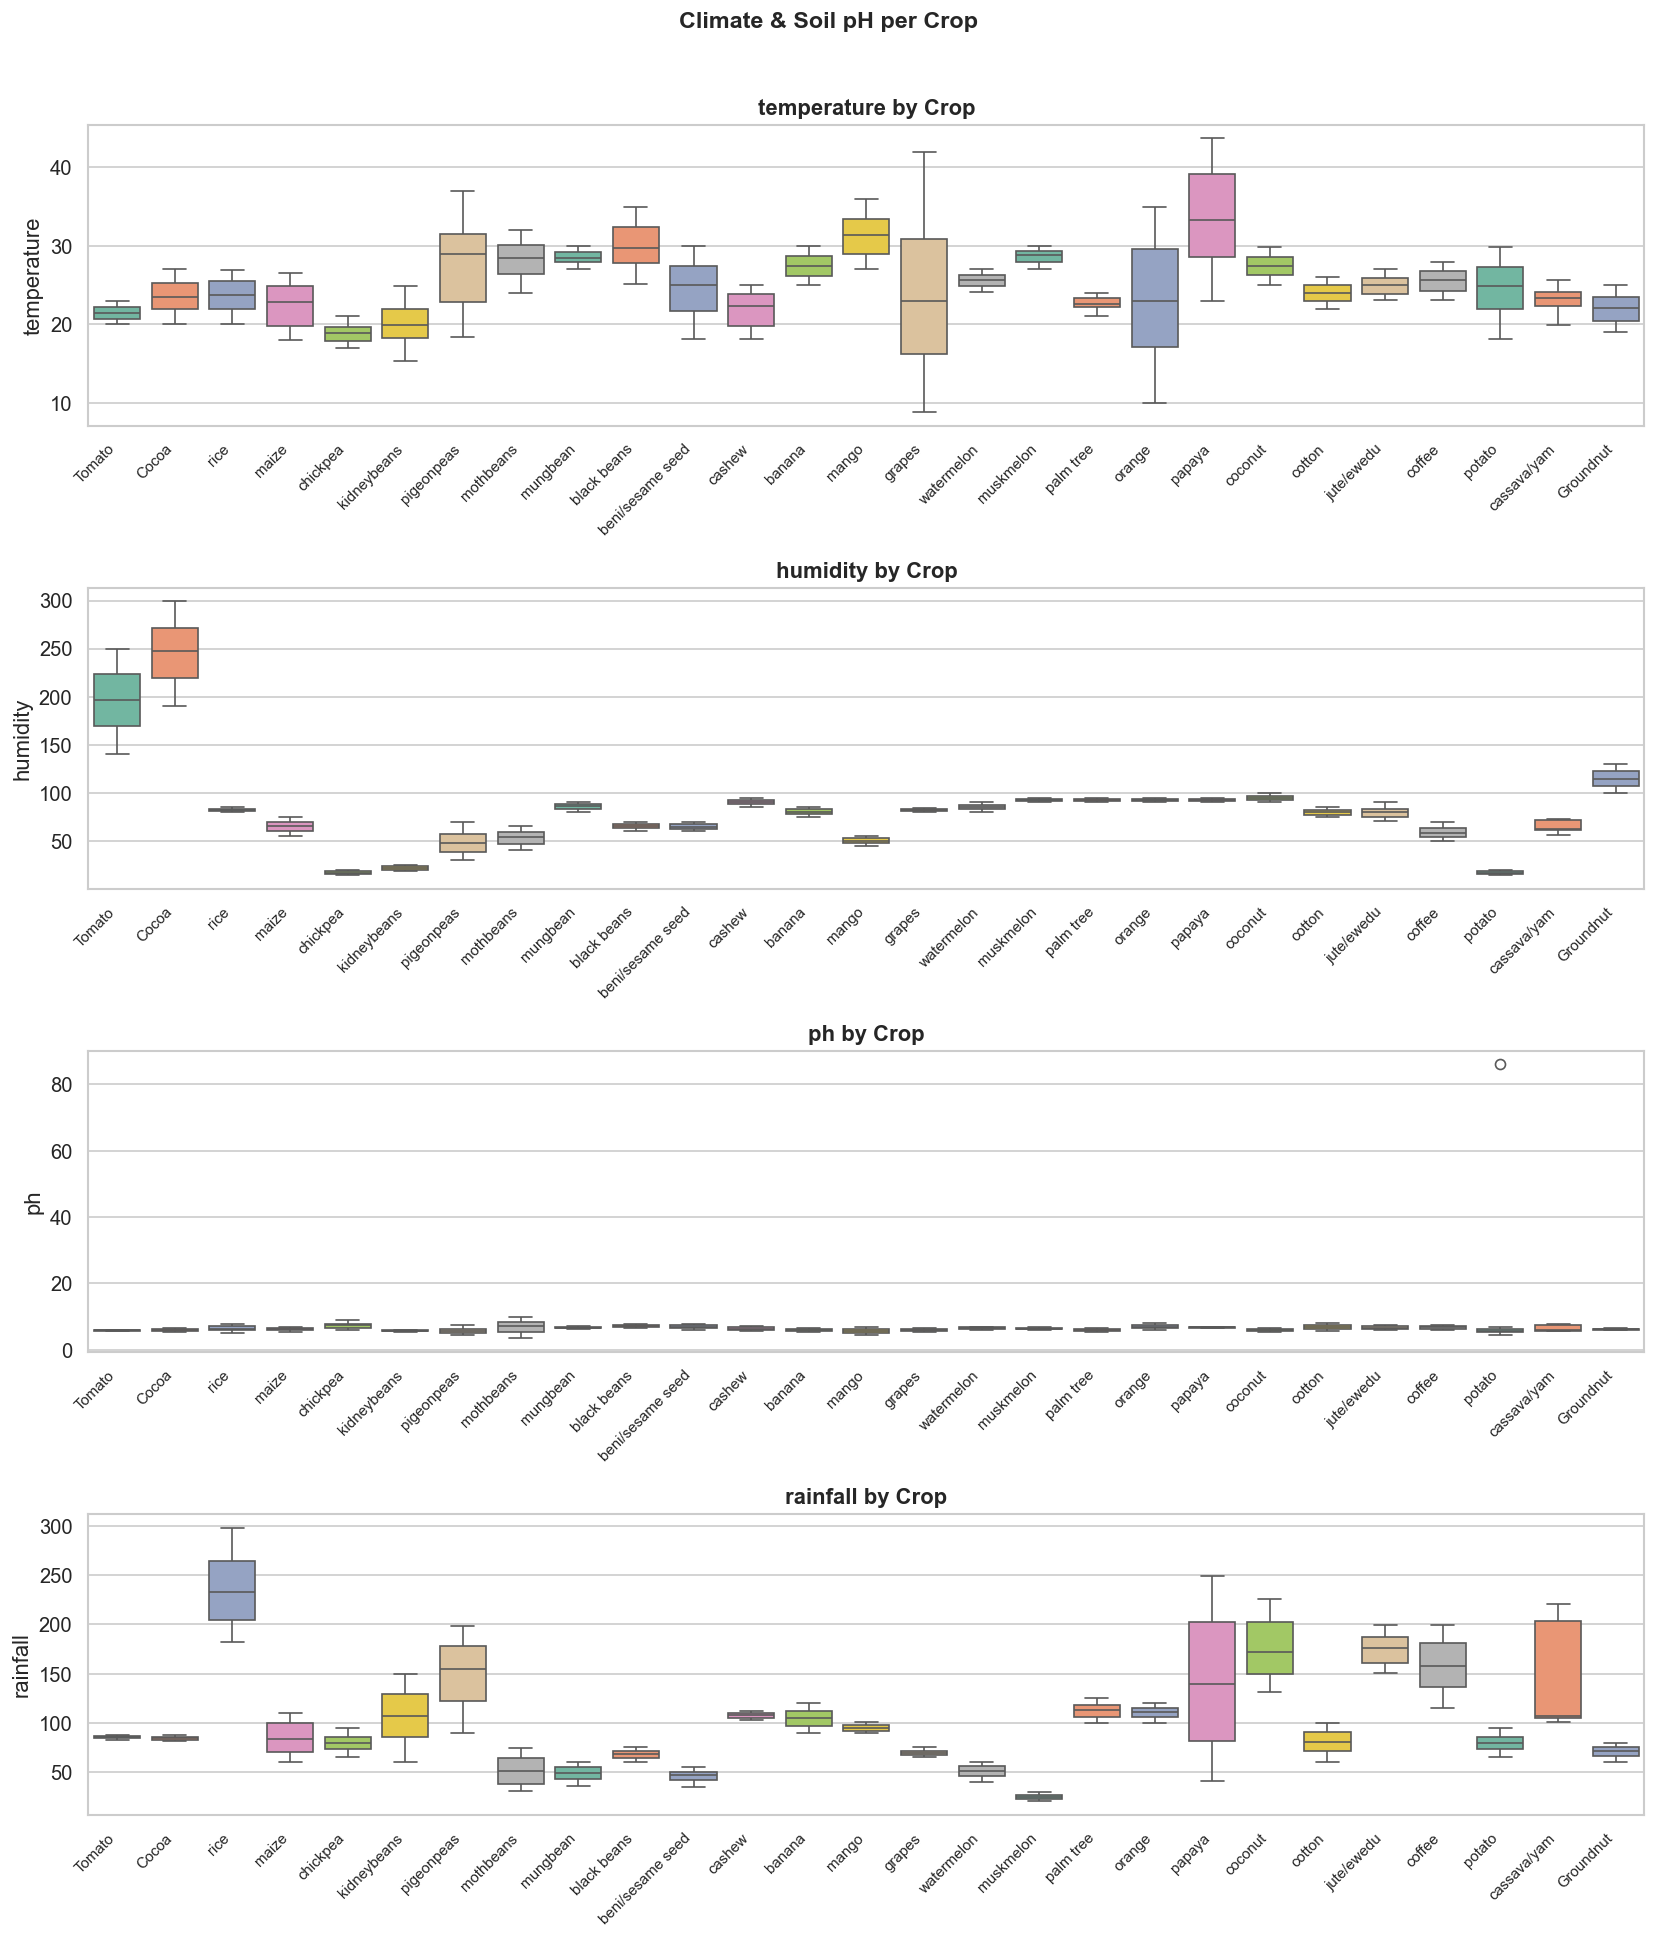

In [10]:
# Boxplots (temperature, humidity, ph, rainfall)
fig, axes = plt.subplots(4, 1, figsize=(14, 16))
for ax, col in zip(axes, ['temperature', 'humidity', 'ph', 'rainfall']):
    sns.boxplot(data=df, x='crop', y=col, palette='Set2', ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax.set_title(f'{col} by Crop', fontweight='bold')
    ax.set_xlabel("")
plt.suptitle("Climate & Soil pH per Crop", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**Temperature:** Most crops prefer temperatures around 20–30°C. Coconut and jute/ewedu show comparatively cooler conditions. Grapes, orange, and watermelon have wider temperature ranges, indicating greater adaptability; papaya appears associated with warmer conditions.

**Humidity:** Rice, coconut, and jute/ewedu show very high humidity, generally between 170–280%. Other crops have much lower, mostly 50–100% humidity. These values above 100% are physically unrealistic for relative humidity and may reflect data-entry or unit errors that should be investigated.

**pH:** Nearly all crops have soil pH values concentrated between 5 and 7, indicating similar slightly acidic conditions. The one point near pH 86 is clearly an outlier and must be removed or corrected; it invalidates the lower portion of the plot scale.

**Rainfall:** Rice is associated with substantially higher rainfall, around 180–280 mm. Coconut, coffee, and jute/ewedu also require moderate-to-high rainfall. Muskmelon, mothbeans, and sesame seed appear to require relatively little rainfall. The wide rice box suggests considerable variation across observations.

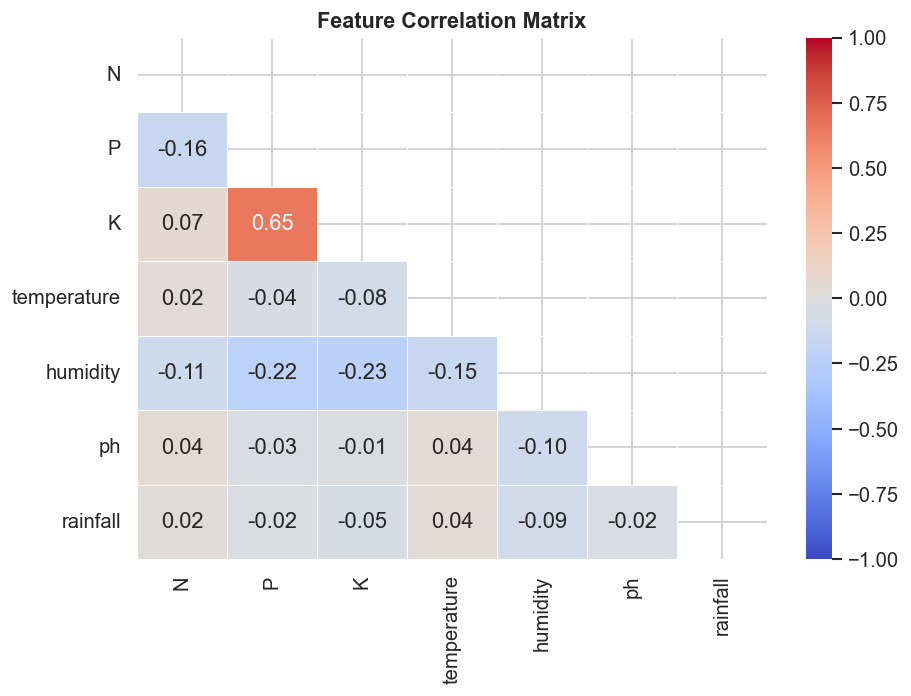

In [11]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', mask=mask,
            linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title("Feature Correlation Matrix", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**P and K:** 0.65 is a Moderate positive correlation. Higher phosphorus values tend to occur with higher potassium values.

**N and other features:** 0.07 to -0.16 is a Very weak relationships. Nitrogen has little linear association with the remaining features.

**Temperature, humidity, rainfall, and pH:** Mostly weak correlations, ranging approximately from -0.23 to 0.04.

The remaining negative correlations indicate that when one feature increases, the other tends to decrease slightly, but the associations are small. For example, humidity has a weak negative relationship with potassium (-0.23) and phosphorus (-0.22).

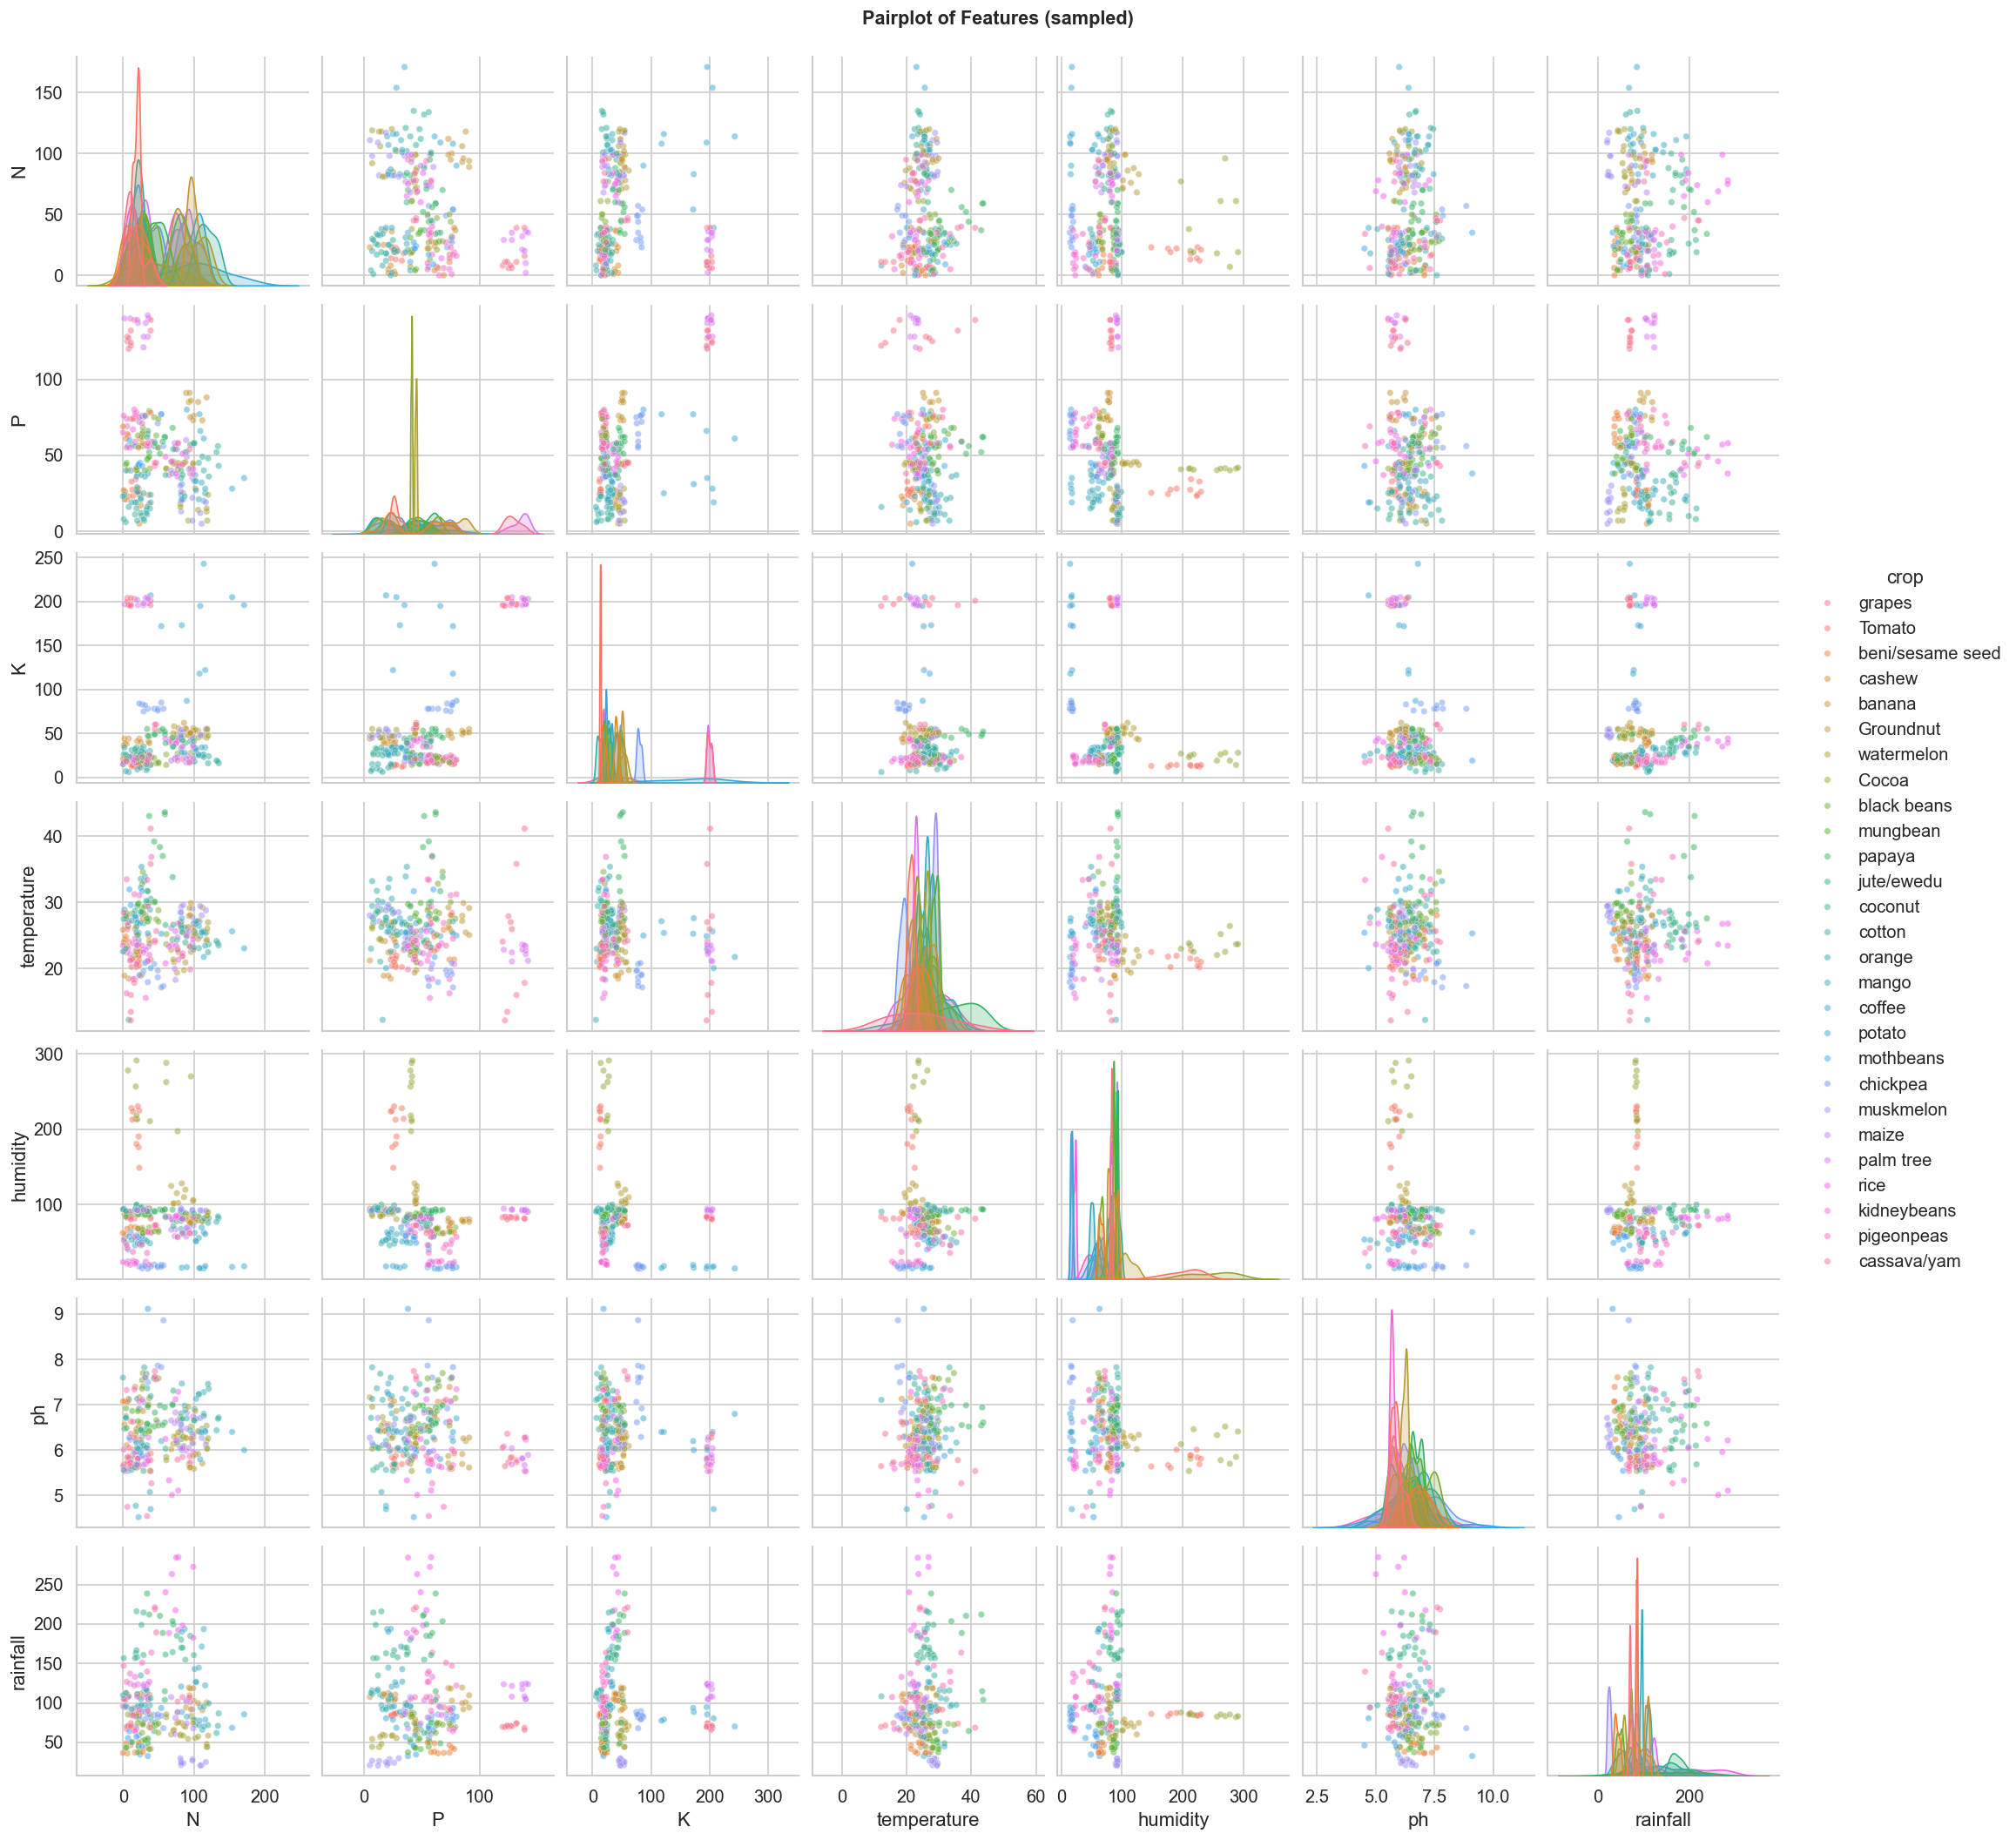

In [12]:
# Pairplot (sampled for speed)
sample = df.sample(frac=1, random_state=42).groupby('crop').head(10).reset_index(drop=True)
pp = sns.pairplot(sample, hue='crop', vars=features, plot_kws={'alpha': 0.5, 's': 20}, diag_kind='kde')
pp.fig.suptitle("Pairplot of Features (sampled)", y=1.01, fontsize=13, fontweight='bold')
plt.show()


## 3. Data Cleaning

**Issues found:**
- `ph` has a maximum of **86.0** — physically impossible (pH scale: 0–14). These are data entry errors.
- Imbalance in the `class` distribution, with cassava/yam having only 7 samples while other crops have 100+ samples.
- All other features are within plausible agronomic ranges.


In [13]:
RANDOM_STATE = 56

# Remove cassava/yam and retain exactly 100 rows from overrepresented classes
df = (
    df[df['crop'] != 'cassava/yam']
      .groupby('crop', group_keys=False)
      .apply(lambda group: group.sample(n=100, random_state=RANDOM_STATE)
             if len(group) > 100 else group)
      .reset_index(drop=True)
)

print("Class distribution after balancing:")
print(df['crop'].value_counts().sort_index())
print(f"\nFinal dataset shape: {df.shape}")

Class distribution after balancing:
crop
Cocoa               100
Groundnut           100
Tomato              100
banana              100
beni/sesame seed    100
black beans         100
cashew              100
chickpea            100
coconut             100
coffee              100
cotton              100
grapes              100
jute/ewedu          100
kidneybeans         100
maize               100
mango               100
mothbeans           100
mungbean            100
muskmelon           100
orange              100
palm tree           100
papaya              100
pigeonpeas          100
potato              100
rice                100
watermelon          100
Name: count, dtype: int64

Final dataset shape: (2600, 8)


In [14]:
# Identify & remove pH outliers (pH > 14 is impossible)
print(f"Rows before cleaning : {len(df):,}")
ph_outliers = df[df['ph'] > 14]
print(f"pH > 14 (impossible) : {len(ph_outliers)} rows")
print(ph_outliers[['ph', 'crop']].to_string())
df_clean = df[df['ph'] <= 14].copy()
print(f"Rows after cleaning  : {len(df_clean):,}")

Rows before cleaning : 2,600
pH > 14 (impossible) : 1 rows
        ph    crop
2301  86.0  potato
Rows after cleaning  : 2,599


In [15]:
# Duplicate check
dupes = df_clean.duplicated().sum()
print(f"Duplicate rows: {dupes}")
df_clean = df_clean.drop_duplicates()
print(f"Rows after deduplication: {len(df_clean):,}")


Duplicate rows: 0
Rows after deduplication: 2,599


In [16]:
# Re-inspect after cleaning
print("Clean dataset summary:")
df_clean.describe().round(3)


Clean dataset summary:


,N,P,K,temperature,humidity,ph,rainfall
count,2599.000,2599.000,2599.000,2599.000,2599.000,2599.000,2599.000
mean,52.649,51.243,49.856,25.177,82.632,6.396,99.892
std,38.146,31.107,52.527,4.866,48.588,0.748,51.342
min,0.000,5.000,5.000,8.826,14.258,3.505,20.211
25%,21.000,29.000,20.000,22.085,60.273,5.910,66.935
50%,39.000,45.040,32.000,25.033,81.592,6.336,87.210
75%,85.500,65.000,50.000,28.035,91.697,6.815,116.059
max,179.000,145.000,250.000,43.675,299.130,9.935,298.560


In [17]:
# Check class distribution again
print(f"Unique crops : {df_clean['crop'].nunique()}")
print("\nCrop value counts:")
print(df_clean['crop'].value_counts())


Unique crops : 26

Crop value counts:
crop
Cocoa               100
Groundnut           100
rice                100
pigeonpeas          100
papaya              100
palm tree           100
orange              100
muskmelon           100
mungbean            100
mothbeans           100
mango               100
maize               100
kidneybeans         100
jute/ewedu          100
grapes              100
cotton              100
coffee              100
coconut             100
chickpea            100
cashew              100
black beans         100
beni/sesame seed    100
banana              100
Tomato              100
watermelon          100
potato               99
Name: count, dtype: int64


## 4. Data Preprocessing, Encoding & Splitting

In [18]:
# Encode target label
le = LabelEncoder()
df_clean['crop_encoded'] = le.fit_transform(df_clean['crop'])
print("Label mapping:")
for idx, cls in enumerate(le.classes_):
    print(f"  {idx:2d} → {cls}")


Label mapping:
   0 → Cocoa
   1 → Groundnut
   2 → Tomato
   3 → banana
   4 → beni/sesame seed
   5 → black beans
   6 → cashew
   7 → chickpea
   8 → coconut
   9 → coffee
  10 → cotton
  11 → grapes
  12 → jute/ewedu
  13 → kidneybeans
  14 → maize
  15 → mango
  16 → mothbeans
  17 → mungbean
  18 → muskmelon
  19 → orange
  20 → palm tree
  21 → papaya
  22 → pigeonpeas
  23 → potato
  24 → rice
  25 → watermelon


In [20]:
# Features / target split
FEATURES = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df_clean[FEATURES].values
y = df_clean['crop_encoded'].values

# Scale features (critical for SVM)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/test split — stratified to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training samples : {X_train.shape[0]:,}")
print(f"Test samples     : {X_test.shape[0]:,}")
print(f"Classes          : {len(le.classes_)}")


Training samples : 2,079
Test samples     : 520
Classes          : 26


In [21]:
X.shape

(2599, 7)

## 5. Model Training

Multiple algorithms chosen for their complementary strengths:
| Model | Why |
|---|---|
| **Random Forest** | Robust ensemble, handles mixed scales, built-in feature importance |
| **Support Vector Machine (SVM)** | Strong on high-dimensional, well-scaled data |
| **Gradient Boosting** | Sequential boosting, typically top performer on tabular data |
| **XGBoost** | Optimized gradient boosting, handles missing values, fast |
| **LightGBM** | Gradient boosting variant, faster on large datasets, handles categorical features |
| **CatBoost** | Gradient boosting variant, handles categorical features natively, robust to overfitting |
| **Stacking Classifier** | Combines multiple models to leverage their strengths, often improves accuracy |


In [22]:
# Define models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import StackingClassifier

models = {
    "Random Forest"       : RandomForestClassifier(n_estimators=200, max_depth=None,
                                                   random_state=42, n_jobs=-1),

    "Support Vector Machine": SVC(kernel='rbf', C=10, gamma='scale', probability=True,
                                  random_state=42),

    "Gradient Boosting"   : GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                       max_depth=5, random_state=42),

    "XGBoost"             : XGBClassifier(n_estimators=200, learning_rate=0.1,
                                           max_depth=5, random_state=42, use_label_encoder=False,
                                           eval_metric='mlogloss'),

    "LightGBM"            : LGBMClassifier(n_estimators=200, learning_rate=0.1,
                                            max_depth=5, random_state=42),

    "CatBoost"            : CatBoostClassifier(n_estimators=200, learning_rate=0.1,
                                            max_depth=5, random_state=42)
}


In [23]:
# Cross-validation comparison
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring='accuracy', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:<30}  CV mean: {scores.mean():.4f}  std: {scores.std():.4f}")


Random Forest                   CV mean: 0.9957  std: 0.0018
Support Vector Machine          CV mean: 0.9832  std: 0.0059
Gradient Boosting               CV mean: 0.9817  std: 0.0071
XGBoost                         CV mean: 0.9875  std: 0.0075
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000982 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000960 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001033 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1451
[LightGBM] [Info] Total Bins 1454
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001003 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Auto-choosing col-wise

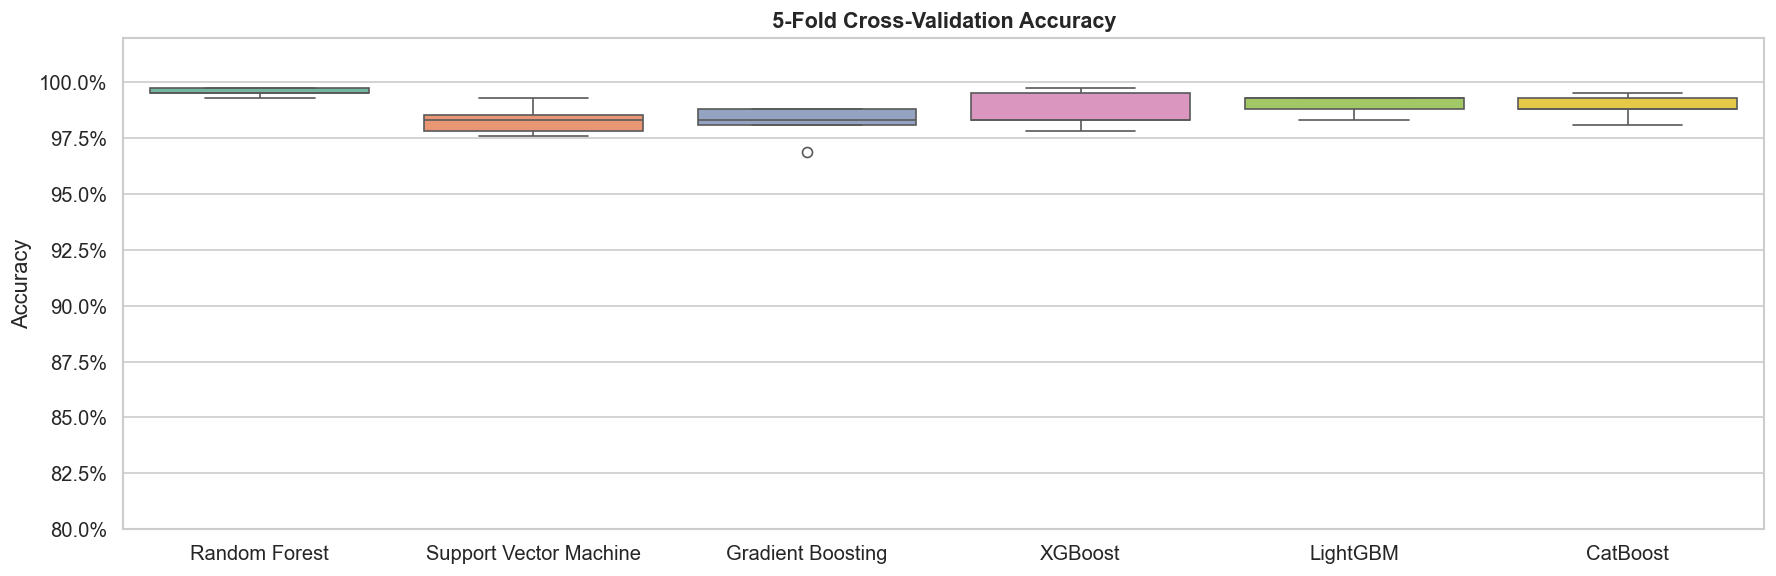

In [24]:
# Visualise CV scores
fig, ax = plt.subplots(figsize=(15, 5))
cv_df = pd.DataFrame(cv_results)
sns.boxplot(data=cv_df, palette='Set2', ax=ax)
ax.set_title("5-Fold Cross-Validation Accuracy", fontsize=13, fontweight='bold')
ax.set_ylabel("Accuracy")
ax.set_ylim(0.8, 1.02)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()


In [25]:
# Train all models on full train set & evaluate on test set
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = {"model": model, "accuracy": acc, "predictions": y_pred}
    print(f"{name:<30}  Test Accuracy: {acc:.4f} ({acc*100:.2f}%)")


Random Forest                   Test Accuracy: 0.9962 (99.62%)
Support Vector Machine          Test Accuracy: 0.9885 (98.85%)
Gradient Boosting               Test Accuracy: 0.9808 (98.08%)
XGBoost                         Test Accuracy: 0.9923 (99.23%)
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000285 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1463
[LightGBM] [Info] Number of data points in the train set: 2079, number of used features: 7
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start training from score -3.257616
[LightGBM] [Info] Start train

## 6. Model Evaluation & Comparison

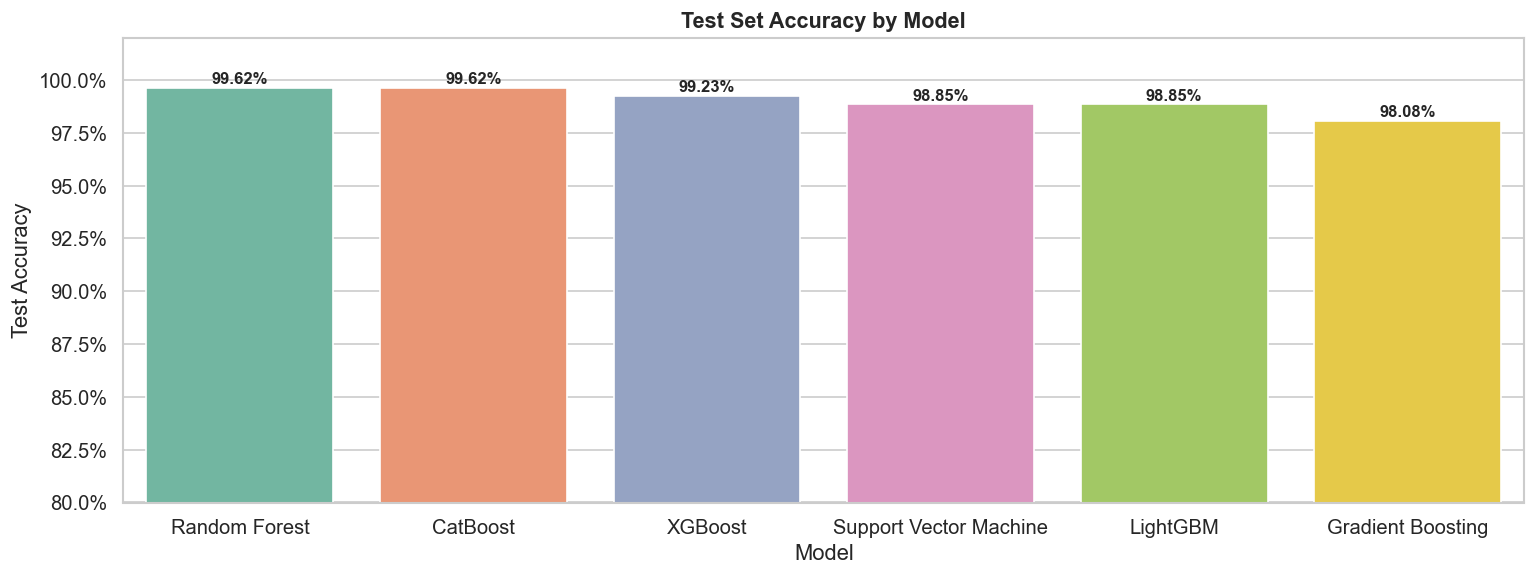

In [26]:
# Accuracy comparison bar chart
acc_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Test Accuracy": [v["accuracy"] for v in results.values()]
}).sort_values("Test Accuracy", ascending=False)

fig, ax = plt.subplots(figsize=(13, 5))
bars = sns.barplot(data=acc_df, x="Model", y="Test Accuracy",
                   palette='Set2', ax=ax, edgecolor='white')
ax.set_ylim(0.8, 1.02)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Test Set Accuracy by Model", fontsize=13, fontweight='bold')
for bar, acc in zip(ax.patches, acc_df["Test Accuracy"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f"{acc*100:.2f}%", ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


In [27]:
# Identify top 3 models
top_three_names = sorted(results, key=lambda k: results[k]["accuracy"], reverse=True)[:3]

for i, name in enumerate(top_three_names, start=1):
    model = results[name]["model"]
    acc = results[name]["accuracy"]
    preds = results[name]["predictions"]
    print(f"{i}. {name}: {acc*100:.2f}%")


1. Random Forest: 99.62%
2. CatBoost: 99.62%
3. XGBoost: 99.23%


In [28]:
# Classification report for top 3 models
for name in top_three_names:
    model = results[name]["model"]
    acc = results[name]["accuracy"]
    preds = results[name]["predictions"]
    print(f"\nClassification Report — {name} (Accuracy: {acc*100:.2f}%)\n")
    print(classification_report(y_test, preds,
                                 target_names=le.classes_, digits=3))



Classification Report — Random Forest (Accuracy: 99.62%)

                  precision    recall  f1-score   support

           Cocoa      1.000     1.000     1.000        20
       Groundnut      1.000     1.000     1.000        20
          Tomato      1.000     1.000     1.000        20
          banana      1.000     1.000     1.000        20
beni/sesame seed      1.000     1.000     1.000        20
     black beans      1.000     0.950     0.974        20
          cashew      1.000     1.000     1.000        20
        chickpea      1.000     1.000     1.000        20
         coconut      1.000     1.000     1.000        20
          coffee      1.000     1.000     1.000        20
          cotton      1.000     1.000     1.000        20
          grapes      1.000     1.000     1.000        20
      jute/ewedu      0.952     1.000     0.976        20
     kidneybeans      1.000     1.000     1.000        20
           maize      0.952     1.000     0.976        20
           m

In [29]:
results

{'Random Forest': {'model': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
  'accuracy': 0.9961538461538462,
  'predictions': array([ 4, 24, 18, 22, 19, 15, 11, 21,  9, 25, 13, 16,  4, 18, 19,  1, 19,
         11, 21,  6,  2, 14, 18,  1, 17, 14,  3,  1,  5, 24,  2,  3,  5,  8,
         21, 20,  9, 12, 13,  4, 14, 19,  6, 25, 25, 19, 24, 21,  6,  3, 23,
          3,  9, 20, 12, 22,  5, 17,  7,  6,  5,  0, 22, 16,  7,  2, 10,  9,
          9, 20,  9,  1, 11, 12,  8, 24, 16, 14,  5, 24, 21, 17,  1, 15, 10,
         25, 17,  1,  8,  8, 25, 25, 18,  7, 12, 18,  6,  4,  7,  8, 14, 23,
         13,  1, 21,  9, 13,  1,  0,  5,  9,  0,  4, 22, 20, 22, 24, 15, 22,
         11, 19,  2, 14,  8, 13, 16, 13,  5, 12, 12, 21, 25, 20,  3, 12, 10,
         16, 10,  7, 12, 13, 21,  0, 23, 20, 13, 15,  2, 15,  7, 22, 22, 11,
          6, 25, 13, 20, 15, 25,  6, 14,  5, 13, 23, 22, 22, 19, 17, 20, 13,
         20,  3, 21, 11, 15, 14,  6,  1, 24, 25,  8, 22,  0, 10, 16, 10, 23,
      

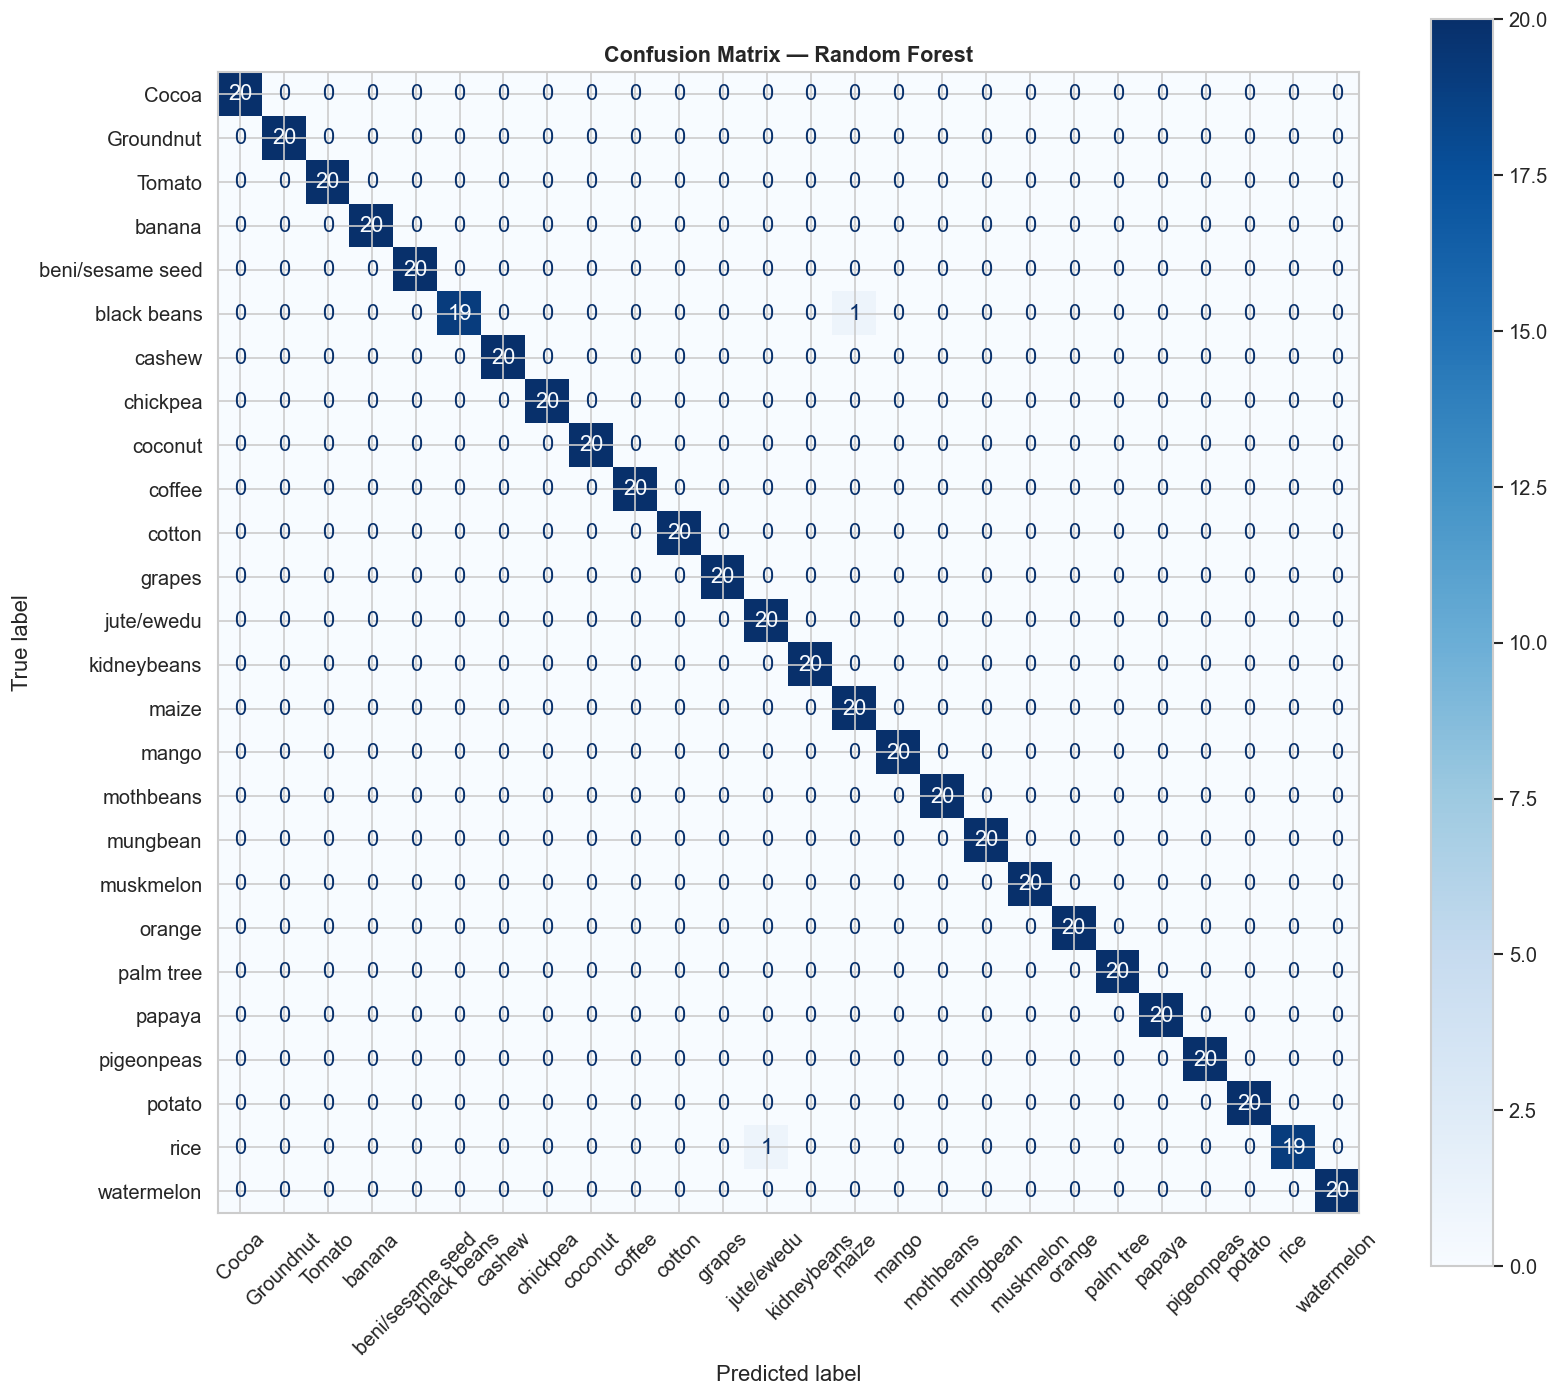

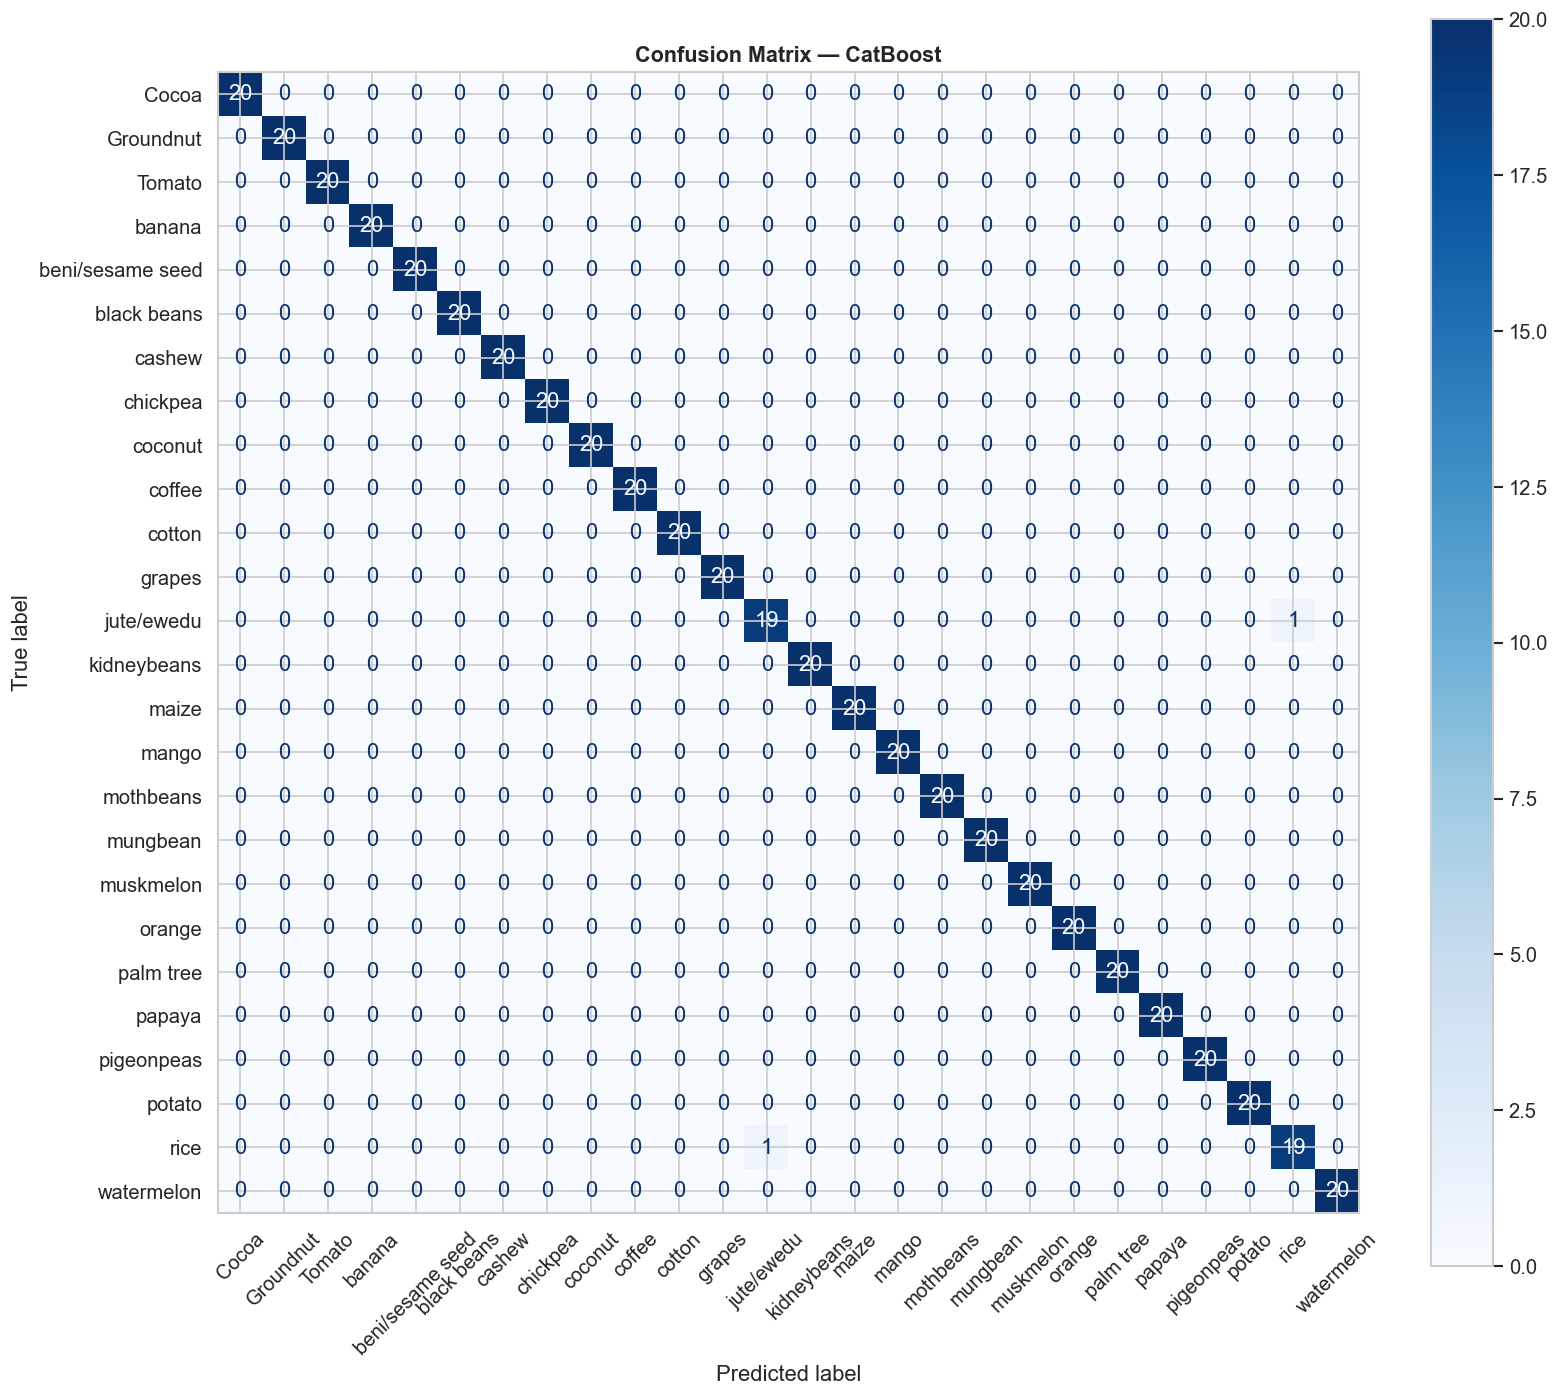

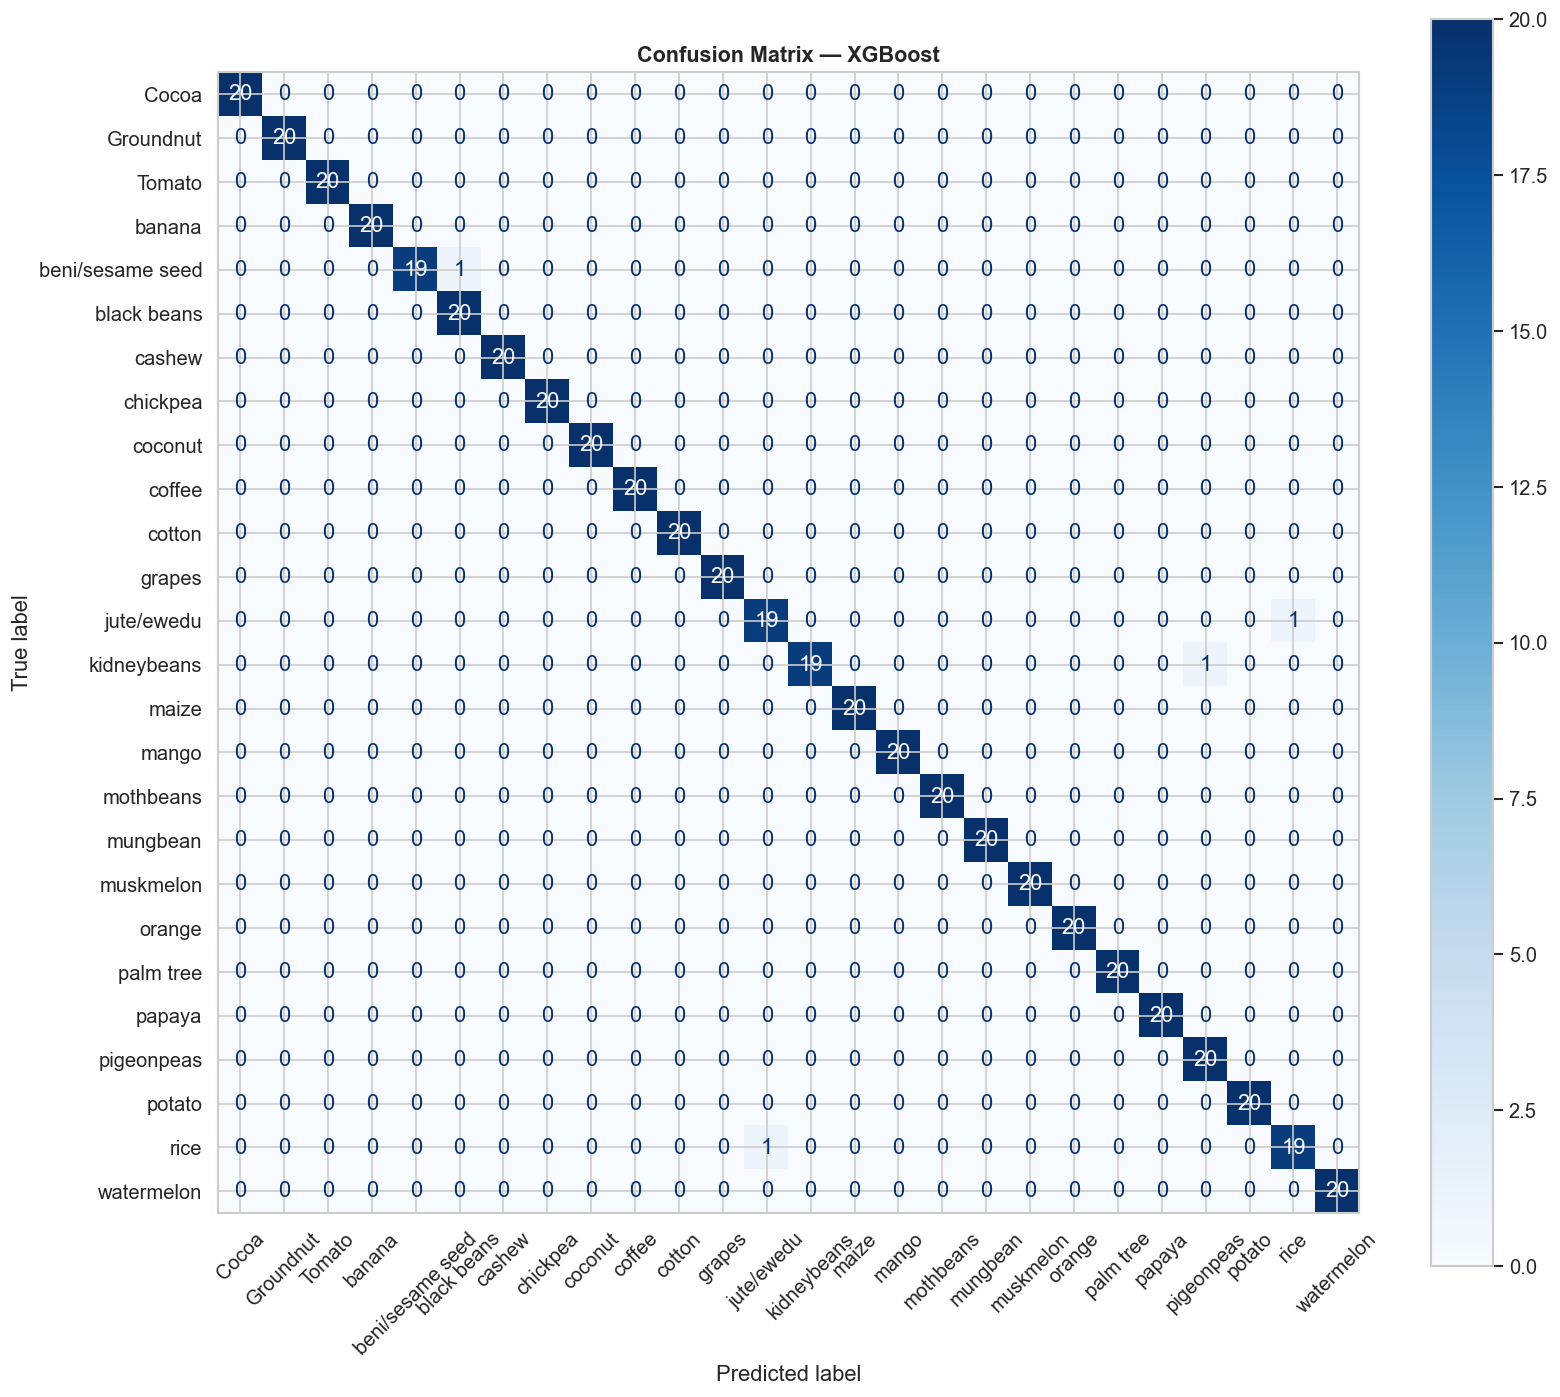

In [30]:
# Confusion matrix for top 3 models
for name in top_three_names:
    model = results[name]["model"]
    acc = results[name]["accuracy"]
    preds = results[name]["predictions"]
    cm = confusion_matrix(y_test, preds)
    fig, ax = plt.subplots(figsize=(14, 12))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=True, cmap='Blues', xticks_rotation=45)
    ax.set_title(f"Confusion Matrix — {name}", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


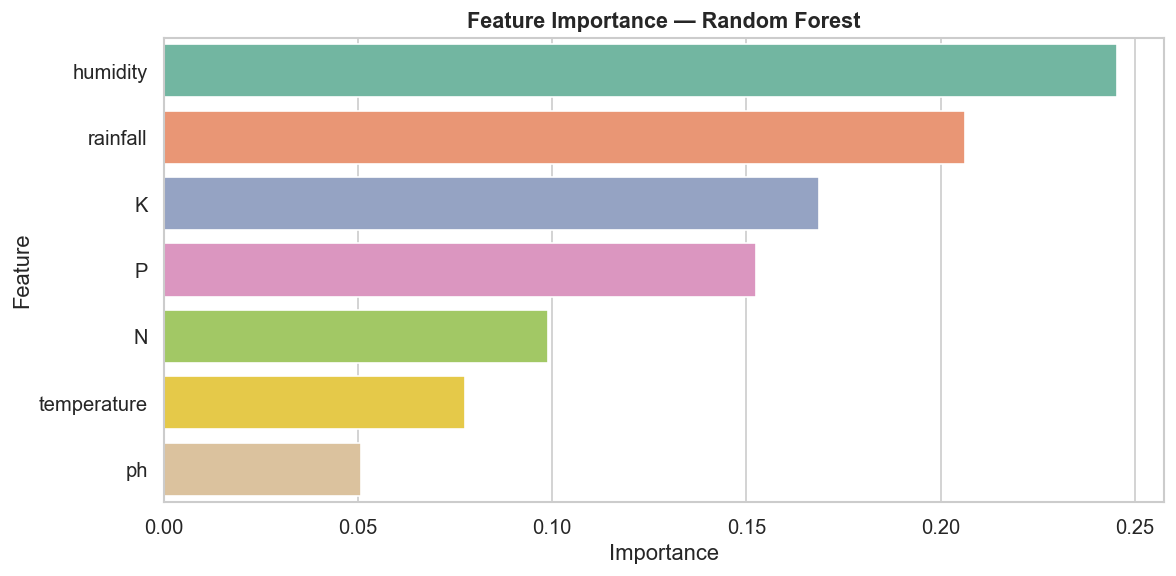

In [31]:
# Feature importance (RF / GB only)
for name in top_three_names:
    if name in ["Random Forest", "Gradient Boosting"]:
        model = results[name]["model"]
        importances = model.feature_importances_
        imp_df = pd.DataFrame({"Feature": FEATURES, "Importance": importances})
        imp_df = imp_df.sort_values("Importance", ascending=False)

        fig, ax = plt.subplots(figsize=(10, 5))
        sns.barplot(data=imp_df, x="Importance", y="Feature", palette='Set2', ax=ax)
        ax.set_title(f"Feature Importance — {name}", fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

In [32]:
from sklearn.linear_model import LogisticRegression

ranked_models = sorted(
    cv_results,
    key=lambda name: cv_results[name].mean(),
    reverse=True
)

top_three_names = ranked_models[:3]

print("Best three models:")
for rank, name in enumerate(top_three_names, start=1):
    print(
        f"{rank}. {name}: "
        f"{cv_results[name].mean():.4f} "
        f"(± {cv_results[name].std():.4f})"
    )

stacking_estimators = [
    (name.replace(" ", "_").lower(), models[name])
    for name in top_three_names
]

stacked_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    cv=5,
    passthrough=False,
    stack_method="predict_proba",
    n_jobs=-1
)

models["Stacking Classifier"] = stacked_model

Best three models:
1. Random Forest: 0.9957 (± 0.0018)
2. LightGBM: 0.9899 (± 0.0038)
3. CatBoost: 0.9889 (± 0.0050)


In [33]:
# Train the stacking model
stacked_model.fit(X_train, y_train)

# Evaluate the stacking model
y_pred_stacked = stacked_model.predict(X_test)
acc_stacked = accuracy_score(y_test, y_pred_stacked)
results["Stacking Classifier"] = {
    "model": stacked_model,
    "accuracy": acc_stacked,
    "predictions": y_pred_stacked
}

# Print the accuracy of the stacking model
print(f"Stacking Classifier Test Accuracy: {acc_stacked:.4f} ({acc_stacked*100:.2f}%)")



0:	learn: 2.6878009	total: 8.41ms	remaining: 1.67s
1:	learn: 2.3505837	total: 15.1ms	remaining: 1.5s
2:	learn: 2.0541349	total: 19.9ms	remaining: 1.3s
3:	learn: 1.7882538	total: 25.1ms	remaining: 1.23s
4:	learn: 1.5832885	total: 29.5ms	remaining: 1.15s
5:	learn: 1.4021449	total: 35ms	remaining: 1.13s
6:	learn: 1.2596971	total: 40ms	remaining: 1.1s
7:	learn: 1.1513184	total: 45.6ms	remaining: 1.09s
8:	learn: 1.0862317	total: 50.2ms	remaining: 1.06s
9:	learn: 0.9926878	total: 54.7ms	remaining: 1.04s
10:	learn: 0.9204047	total: 60.6ms	remaining: 1.04s
11:	learn: 0.8607559	total: 65.9ms	remaining: 1.03s
12:	learn: 0.8020337	total: 70.7ms	remaining: 1.02s
13:	learn: 0.7479887	total: 76ms	remaining: 1.01s
14:	learn: 0.7021160	total: 81.5ms	remaining: 1s
15:	learn: 0.6475065	total: 87ms	remaining: 1000ms
16:	learn: 0.6189805	total: 92.2ms	remaining: 992ms
17:	learn: 0.5839497	total: 98.1ms	remaining: 992ms
18:	learn: 0.5483758	total: 104ms	remaining: 986ms
19:	learn: 0.5151537	total: 109ms	re

Exception ignored in: <function ResourceTracker.__del__ at 0x10766d9e0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

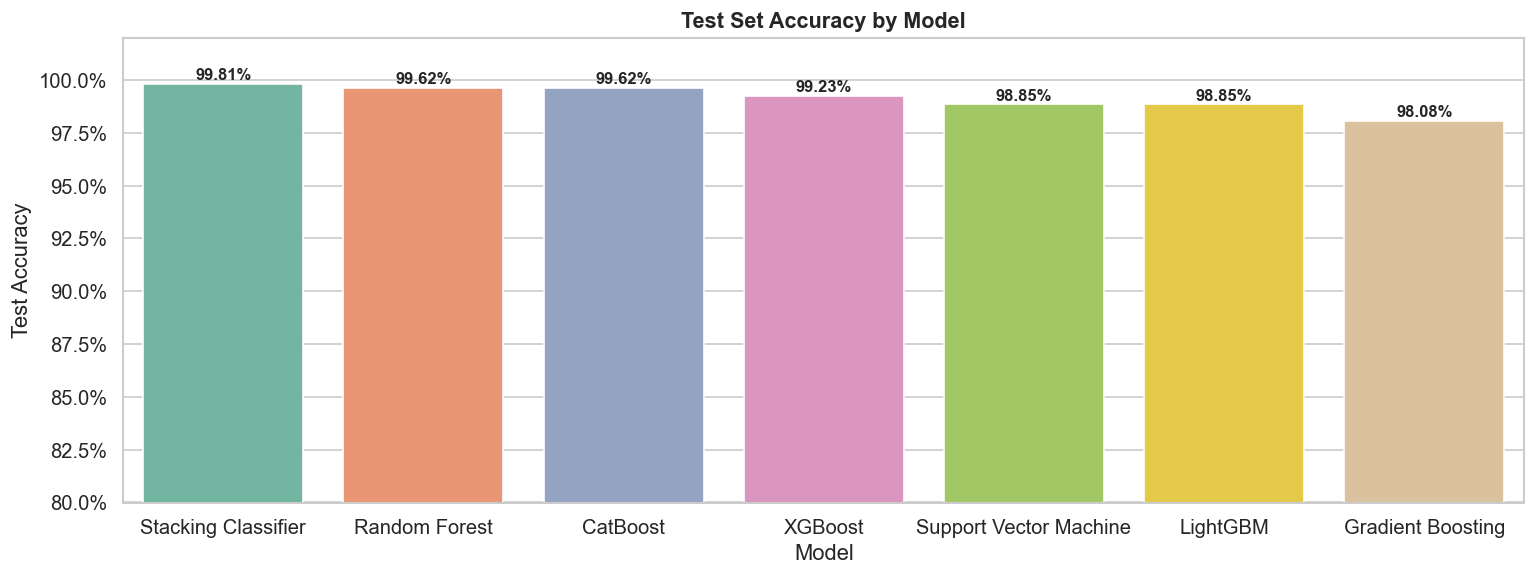

In [34]:
# plot of performance of all models including the stacking classifier
acc_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Test Accuracy": [v["accuracy"] for v in results.values()]
}).sort_values("Test Accuracy", ascending=False)


fig, ax = plt.subplots(figsize=(13, 5))
bars = sns.barplot(data=acc_df, x="Model", y="Test Accuracy",
                   palette='Set2', ax=ax, edgecolor='white')
ax.set_ylim(0.8, 1.02)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Test Set Accuracy by Model", fontsize=13, fontweight='bold')
for bar, acc in zip(ax.patches, acc_df["Test Accuracy"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f"{acc*100:.2f}%", ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Save Artefacts for Streamlit Deployment

In [35]:
# save the best model (highest accuracy) to disk
best_name = max(results, key=lambda k: results[k]["accuracy"])
best_model = results[best_name]["model"]
best_acc = results[best_name]["accuracy"]

In [ ]:
# Persist model, scaler, label encoder
os.makedirs("artifacts", exist_ok=True)

joblib.dump(best_model,   f"artifacts/crop_model_{best_name}.pkl")
joblib.dump(scaler,       "artifacts/scaler.pkl")
joblib.dump(le,           "artifacts/label_encoder.pkl")
joblib.dump(FEATURES,     "artifacts/features.pkl")

print("Saved:")
print(f"  artifacts/crop_model_{best_name}.pkl")
print("  artifacts/scaler.pkl")
print("  artifacts/label_encoder.pkl")
print("  artifacts/features.pkl")
print(f"\nDeployed model : {best_name}")
print(f"Test accuracy  : {best_acc*100:.2f}%")
print(f"Classes        : {len(le.classes_)}")


Saved:
  artifacts/crop_model_Random Forest.pkl
  artifacts/scaler.pkl
  artifacts/label_encoder.pkl
  artifacts/features.pkl

Deployed model : Random Forest
Test accuracy  : 99.62%
Classes        : 26


Exception ignored in: <function ResourceTracker.__del__ at 0x1067399e0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104eed9e0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/m

In [37]:
df_clean

,N,P,K,temperature,humidity,ph,rainfall,crop,crop_encoded
0,83,41.81,17,22.750000,244.500000,5.850000,86.770000,Cocoa,0
1,10,41.48,20,25.310000,263.030000,6.500000,82.910000,Cocoa,0
2,69,42.09,19,22.100000,262.480000,5.890000,81.270000,Cocoa,0
3,8,41.51,21,23.270000,232.370000,5.790000,87.210000,Cocoa,0
4,55,41.74,29,25.020000,234.370000,5.810000,85.720000,Cocoa,0
...,...,...,...,...,...,...,...,...,...
2595,97,12.00,47,25.287846,89.636679,6.765095,58.286977,watermelon,25
2596,110,7.00,45,26.638386,84.695469,6.189214,48.324286,watermelon,25
2597,96,18.00,50,25.331045,84.305338,6.904242,41.532187,watermelon,25
2598,83,23.00,55,26.897502,83.892415,6.463271,43.971937,watermelon,25


Exception ignored in: <function ResourceTracker.__del__ at 0x1046c59e0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1088399e0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/m